In [155]:
%load_ext autoreload
%autoreload 2

from collections.abc import Sequence
from functools import partial
from itertools import pairwise

import numpy as np
import optuna
import pandas as pd
from IPython.display import display
from optuna.study import MaxTrialsCallback
from optuna.trial import TrialState
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import Pipeline

import matplotlib.pyplot as plt
import seaborn as sns

from TrailPredictor.dataset import Dataset

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [156]:
dataset = Dataset.load(min_distance=40, max_distance=100, segment_width=500)
plotter = dataset.plot

In [157]:
dataset.target = "pace"
RANDOM_STATE = 42

## Optimisation des seuils de zones cardiaques (Optuna)

Seule la définition des zones change d'un essai à l'autre : pour N zones, Optuna propose N-1 seuils
croissants, les features sont reconstruites avec `build_features(..., heart_rate_zones=...)`, puis le pipeline
est évalué en `GroupKFold(5)` par `activity_id`. Une étude par N ∈ {3, 4, 5, 6}, puis choix de N par la règle du 1-SE.

In [158]:
# --- Paramètres de la recherche ---
ZONE_COUNTS = (2, 3, 4, 5, 6, 7)  # nombres de zones N testés (une étude Optuna par N)
N_TRIALS = (
    10  # nombre d'essais *terminés* par étude (les essais élagués ne comptent pas)
)
MAX_TRIALS_FACTOR = (
    20  # garde-fou : au plus N_TRIALS * MAX_TRIALS_FACTOR essais, élagués compris
)
N_SPLITS = 5  # GroupKFold externe (évaluation) et interne (LassoCV)
SEED = 0

FIRST_CUT_RANGE = (120, 170)  # bornes de c1, en bpm
GAP_RANGE = (4, 30)  # bornes des écarts entre seuils successifs, en bpm
MAX_LAST_CUT = 188  # au-delà, l'essai est élagué (bpm)
HR_FLOOR_BPM, HR_CEIL_BPM = 0, 250  # bornes extrêmes : couvrent toutes les FC observées
# couleurs des zones Z0 … Z9 (palette tab10), utilisées dans toutes les figures
ZONE_COLORS = (
    "#1f77b4",
    "#ff7f0e",
    "#2ca02c",
    "#d62728",
    "#9467bd",
    "#8c564b",
    "#e377c2",
    "#7f7f7f",
    "#bcbd22",
    "#17becf",
)
assert len(ZONE_COLORS) >= max(ZONE_COUNTS)

In [159]:
def cuts_to_zones(cuts: Sequence[int]) -> dict[str, tuple[int, int]]:
    """Convertit N-1 seuils croissants (bpm) en N zones contiguës Z0 … Z{N-1}."""
    bounds = [HR_FLOOR_BPM, *cuts, HR_CEIL_BPM]
    assert all(
        lo < hi for lo, hi in pairwise(bounds)
    ), f"Seuils non strictement croissants : {cuts}"
    return {f"Z{k}": (lo, hi) for k, (lo, hi) in enumerate(pairwise(bounds))}


def cuts_to_params(cuts: Sequence[int]) -> dict[str, int]:
    """Traduit des seuils en paramètres Optuna (c1 puis écarts gap_k = c_k - c_{k-1})."""
    return {"c1": cuts[0]} | {
        f"gap_{k}": cuts[k - 1] - cuts[k - 2] for k in range(2, len(cuts) + 1)
    }


REFERENCE_CUTS = [142, 161, 170, 183]  # , 189]
assert cuts_to_zones([142, 161]) == {"Z0": (0, 142), "Z1": (142, 161), "Z2": (161, 250)}
cuts_to_zones(REFERENCE_CUTS)

{'Z0': (0, 142),
 'Z1': (142, 161),
 'Z2': (161, 170),
 'Z3': (170, 183),
 'Z4': (183, 250)}

In [160]:
def evaluate_cuts_zones(
    cuts: Sequence[int], require_full_coverage: bool = True
) -> tuple[float, float]:
    """RMSE moyen en GroupKFold par activité, et son erreur standard, pour une définition des zones."""
    zones = cuts_to_zones(cuts)

    # features and target construction
    dataset.build_features(heart_rate_zones=zones)
    y = dataset.target
    X = dataset.predictors
    groups = dataset.data["activity_id"]

    pipeline = Pipeline(
        [
            ("preprocess", dataset.get_preprocess()),
            ("regression", LinearRegression()),
        ]
    )

    # Folds are precomputed from `groups`, so no `groups=` and no metadata routing needed
    scores = cross_validate(
        pipeline,
        X,
        y,
        scoring="neg_root_mean_squared_error",
        cv=list(GroupKFold(n_splits=5).split(X, y, groups)),
        error_score="raise",
    )
    fold_rmse = -scores["test_score"]
    return float(fold_rmse.mean()), float(
        fold_rmse.std(ddof=1) / np.sqrt(fold_rmse.size)
    )


# Référence : zones actuelles (bornes 0–210, d'où le contrôle de couverture désactivé)
REFERENCE_RMSE, REFERENCE_SE = evaluate_cuts_zones(
    REFERENCE_CUTS, require_full_coverage=False
)
f"RMSE de référence (HEART_RATE_ZONES) : {REFERENCE_RMSE:.4f} ± {REFERENCE_SE:.4f}"

'RMSE de référence (HEART_RATE_ZONES) : 1.9194 ± 0.2747'

In [161]:
def suggest_cuts(trial: optuna.Trial, n_zones: int) -> list[int]:
    """Propose N-1 seuils croissants : c1, puis des écarts positifs gap_k."""
    cuts = [trial.suggest_int("c1", *FIRST_CUT_RANGE)]
    for k in range(2, n_zones):  # boucle sur les paramètres, pas sur les données
        cuts.append(cuts[-1] + trial.suggest_int(f"gap_{k}", *GAP_RANGE))
    return cuts


def objective(trial: optuna.Trial, n_zones: int) -> float:
    """RMSE moyen en GroupKFold pour les zones proposées par l'essai."""
    cuts = suggest_cuts(trial, n_zones)
    trial.set_user_attr("cuts", cuts)
    if cuts[-1] > MAX_LAST_CUT:
        raise optuna.TrialPruned()  # élagage immédiat, avant tout calcul coûteux
    rmse, rmse_se = evaluate_cuts_zones(cuts)
    trial.set_user_attr("rmse_se", rmse_se)
    return rmse


studies: dict[int, optuna.Study] = {}
for n_zones in ZONE_COUNTS:
    study = optuna.create_study(
        study_name=f"heart_rate_zones_{n_zones}",
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=SEED, multivariate=True),
    )
    if len(REFERENCE_CUTS) == n_zones - 1:
        # NB : le dernier seuil de référence (189) dépasse MAX_LAST_CUT, cet essai sera élagué
        study.enqueue_trial(cuts_to_params(REFERENCE_CUTS))
    study.optimize(
        partial(objective, n_zones=n_zones),
        n_trials=N_TRIALS * MAX_TRIALS_FACTOR,
        # on s'arrête après N_TRIALS essais terminés : les élagués (gratuits) ne consomment pas le budget
        callbacks=[MaxTrialsCallback(N_TRIALS, states=(TrialState.COMPLETE,))],
    )
    studies[n_zones] = study

[I 2026-11-15 20:37:41,585] A new study created in memory with name: heart_rate_zones_2
[I 2026-11-15 20:37:41,875] Trial 0 finished with value: 1.998961843851737 and parameters: {'c1': 147}. Best is trial 0 with value: 1.998961843851737.
[I 2026-11-15 20:37:42,202] Trial 1 finished with value: 1.9274661024672182 and parameters: {'c1': 156}. Best is trial 1 with value: 1.9274661024672182.
[I 2026-11-15 20:37:42,528] Trial 2 finished with value: 1.942932449356308 and parameters: {'c1': 150}. Best is trial 1 with value: 1.9274661024672182.
[I 2026-11-15 20:37:42,841] Trial 3 finished with value: 1.998961843851737 and parameters: {'c1': 147}. Best is trial 1 with value: 1.9274661024672182.
[I 2026-11-15 20:37:43,133] Trial 4 finished with value: 2.101632551081594 and parameters: {'c1': 141}. Best is trial 1 with value: 1.9274661024672182.
[I 2026-11-15 20:37:43,441] Trial 5 finished with value: 1.9404216642475312 and parameters: {'c1': 152}. Best is trial 1 with value: 1.9274661024672182.

In [162]:
def summarize_study(study: optuna.Study, n_zones: int) -> dict:
    """Ligne du tableau récapitulatif : meilleurs seuils et RMSE ± erreur standard."""
    best = study.best_trial
    states = pd.Series([t.state.name for t in study.trials])
    return {
        "n_zones": n_zones,
        "cuts": best.user_attrs["cuts"],
        "rmse": best.value,
        "rmse_se": best.user_attrs["rmse_se"],
        "n_complete": int(states.eq("COMPLETE").sum()),
        "n_pruned": int(states.eq("PRUNED").sum()),
    }


summary = (
    pd.DataFrame([summarize_study(study, n) for n, study in studies.items()])
    .set_index("n_zones")
    .assign(
        reference_rmse=REFERENCE_RMSE,
        reference_se=REFERENCE_SE,
        delta_vs_reference=lambda df: df["rmse"] - REFERENCE_RMSE,
    )
)

# Règle du 1-SE : le plus petit N dont le RMSE reste sous (meilleur RMSE + son erreur standard)
best = summary.nsmallest(1, "rmse").iloc[0]  # row with the lowest RMSE
best_n = best.name
one_se_threshold = best["rmse"] + best["rmse_se"]
SELECTED_N = summary.index[summary["rmse"] <= one_se_threshold].min()
SELECTED_ZONES = cuts_to_zones(summary["cuts"].loc[SELECTED_N])

display(
    summary.assign(
        **{
            "RMSE ± SE": summary["rmse"].map("{:.4f}".format)
            + " ± "
            + summary["rmse_se"].map("{:.4f}".format),
            "référence ± SE": f"{REFERENCE_RMSE:.4f} ± {REFERENCE_SE:.4f}",
            "retenu (1-SE)": summary.index == SELECTED_N,
        }
    )[
        [
            "cuts",
            "RMSE ± SE",
            "référence ± SE",
            "delta_vs_reference",
            "n_complete",
            "n_pruned",
            "retenu (1-SE)",
        ]
    ]
)
f"Meilleur N = {best_n}, seuil 1-SE = {one_se_threshold:.4f} -> N retenu = {SELECTED_N} : {SELECTED_ZONES}"

,cuts,RMSE ± SE,référence ± SE,delta_vs_reference,n_complete,n_pruned,retenu (1-SE)
n_zones,,,,,,,
2,[156],1.9275 ± 0.2580,1.9194 ± 0.2747,0.008055,10,0,True
3,"[150, 168]",1.8688 ± 0.2447,1.9194 ± 0.2747,-0.050650,10,0,False
4,"[136, 164, 179]",1.8837 ± 0.2147,1.9194 ± 0.2747,-0.035670,10,6,False
5,"[152, 162, 166, 175]",1.8543 ± 0.2376,1.9194 ± 0.2747,-0.065155,10,8,False
6,"[123, 150, 163, 180, 185]",1.8510 ± 0.2516,1.9194 ± 0.2747,-0.068415,10,63,False
7,"[125, 129, 147, 151, 167, 175]",1.8698 ± 0.2702,1.9194 ± 0.2747,-0.049622,10,103,False


"Meilleur N = 6, seuil 1-SE = 2.1026 -> N retenu = 2 : {'Z0': (0, 156), 'Z1': (156, 250)}"

In [163]:
all_trials = pd.concat(
    [
        pd.DataFrame(
            {
                "n_zones": n,
                "trial_number": [t.number for t in study.trials],
                "rmse": [t.value for t in study.trials],
                "rmse_se": [t.user_attrs.get("rmse_se") for t in study.trials],
                "cuts": [t.user_attrs.get("cuts") for t in study.trials],
                "state": [t.state.name for t in study.trials],
            }
        )
        for n, study in studies.items()
    ]
)
all_trials

,n_zones,trial_number,rmse,rmse_se,cuts,state
0,2,0,1.998962,0.269812,[147],COMPLETE
1,2,1,1.927466,0.258030,[156],COMPLETE
2,2,2,1.942932,0.261315,[150],COMPLETE
3,2,3,1.998962,0.269812,[147],COMPLETE
4,2,4,2.101633,0.317978,[141],COMPLETE
...,...,...,...,...,...,...
108,7,108,1.896336,0.280145,"[124, 128, 146, 150, 170, 178]",COMPLETE
109,7,109,1.869789,0.270225,"[125, 129, 147, 151, 167, 175]",COMPLETE
110,7,110,1.894469,0.283537,"[124, 129, 146, 152, 169, 177]",COMPLETE
111,7,111,1.896349,0.280114,"[124, 128, 146, 150, 169, 179]",COMPLETE


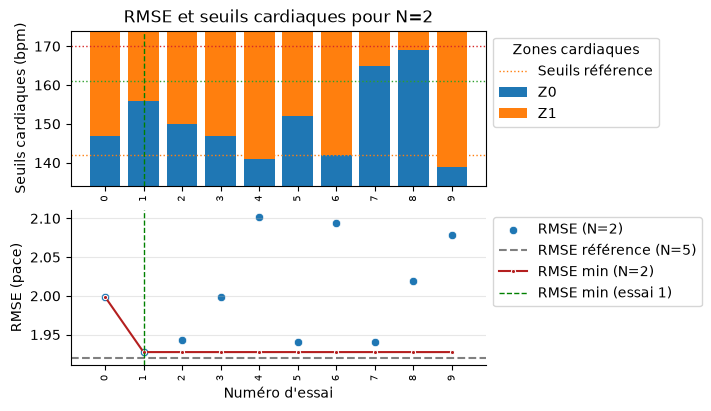

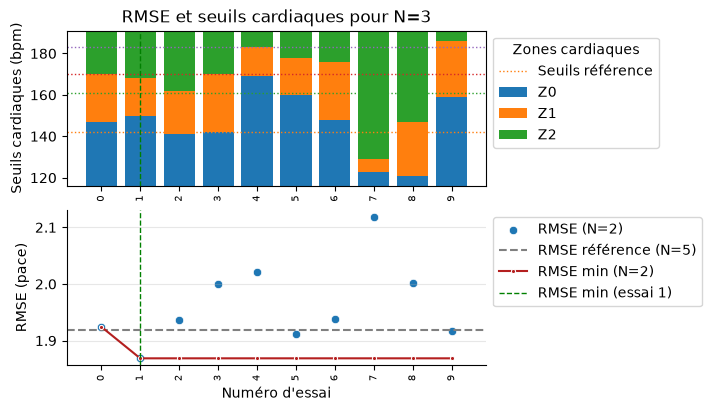

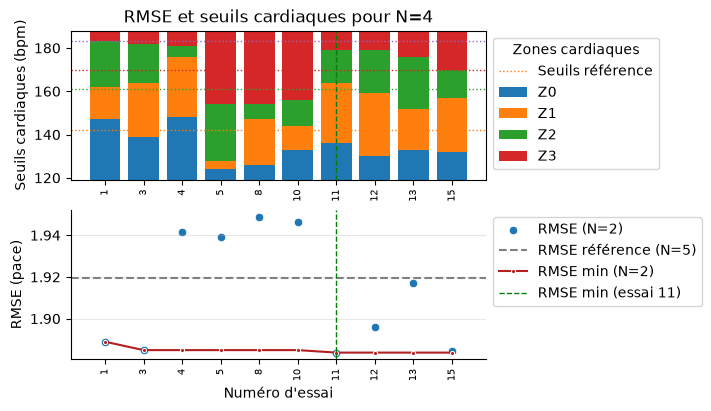

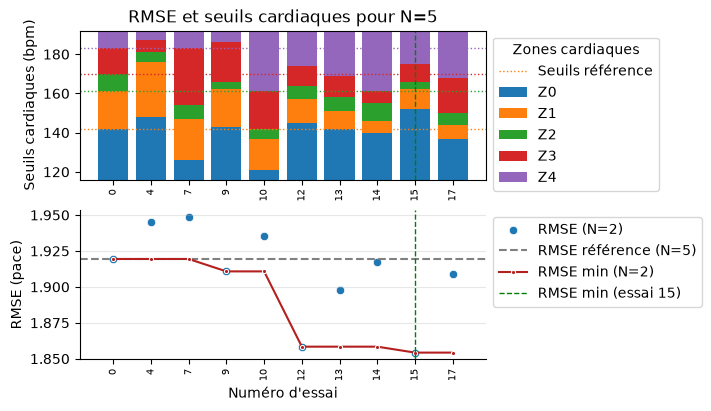

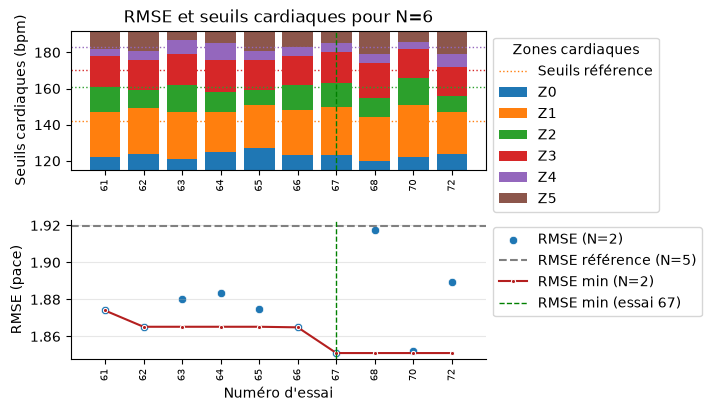

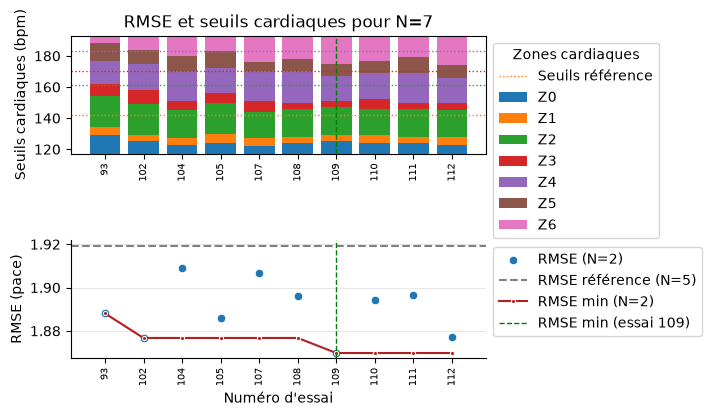

In [164]:
def plot_trials_zones(all_trials: pd.DataFrame, n: int):
    x = all_trials.query("state == 'COMPLETE' and n_zones == @n").sort_values(
        "trial_number"
    )
    x["best_rmse"] = [min(x["rmse"][:i]) for i in range(1, len(x) + 1)]

    fig, axes = plt.subplots(
        figsize=(7, 4), nrows=2, ncols=1, sharex=True, constrained_layout=True
    )

    # floating stacked bars: each segment spans [c_{k-1}, c_k], from c1 up to the last cut
    zones = np.array(
        [
            [z[0] for z in cuts_to_zones(cuts).values()] + [HR_CEIL_BPM]
            for cuts in x["cuts"].to_numpy()
        ]
    )
    # evenly spaced positions: pruned trials leave gaps in trial_number
    positions = np.arange(len(x))
    for k in range(1, zones.shape[1]):
        axes[0].bar(
            positions,
            zones[:, k] - zones[:, k - 1],
            bottom=zones[:, k - 1],
            width=0.8,
            color=ZONE_COLORS[k - 1],
            label=f"Z{k - 1}",
        )

    # RMSE line plot
    sns.scatterplot(
        x=positions,
        y=x["rmse"].to_numpy(),
        marker="o",
        ax=axes[1],
        label=f"RMSE (N={SELECTED_N})",
    )
    axes[1].axhline(
        y=REFERENCE_RMSE,
        color="gray",
        linestyle="--",
        label=f"RMSE référence (N={len(REFERENCE_CUTS) + 1})",
    )
    sns.lineplot(
        x=positions,
        y=x["best_rmse"].to_numpy(),
        marker=".",
        ax=axes[1],
        color="#b41f1f",
        label=f"RMSE min (N={SELECTED_N})",
    )

    # title, axes labels and limits
    axes[0].set_title(f"RMSE et seuils cardiaques pour N={n}")
    axes[0].set_ylabel("Seuils cardiaques (bpm)")
    axes[0].set_ylim(zones[:, 1].min() - 5, zones[:, -2].max() + 5)

    axes[1].set_ylabel(f"RMSE ({dataset.target_name})")
    axes[1].set_xlabel("Numéro d'essai")
    axes[1].set_xticks(positions, x["trial_number"], rotation=90, fontsize=7)
    axes[0].tick_params(axis="x", labelbottom=True, labelrotation=90, labelsize=7)

    axes[1].grid(axis="y", alpha=0.3)
    axes[1].spines[["top", "right"]].set_visible(False)

    # reference cuts as horizontal lines, coloured like the zone they open
    # (cut c_{k+1} is the lower bound of Z{k+1}); single legend entry
    for k, cut in enumerate(REFERENCE_CUTS):
        axes[0].axhline(
            y=cut,
            color=ZONE_COLORS[k + 1],
            linestyle=":",
            linewidth=1,
            label="Seuils référence" if k == 0 else "_nolegend_",
        )

    # highlight the trial with the lowest RMSE on both axes
    best_position = int(np.argmin(x["rmse"].to_numpy()))
    for ax, label in zip(
        axes,
        ["_nolegend_", f"RMSE min (essai {x['trial_number'].iloc[best_position]})"],
        strict=True,
    ):
        ax.axvline(
            x=best_position, color="green", linestyle="--", linewidth=1, label=label
        )

    # legends
    axes[0].legend(title="Zones cardiaques", loc="upper left", bbox_to_anchor=(1, 1))
    _ = axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))
    return fig, axes


for n in ZONE_COUNTS:
    fig, axes = plot_trials_zones(all_trials, n)
    plt.show()

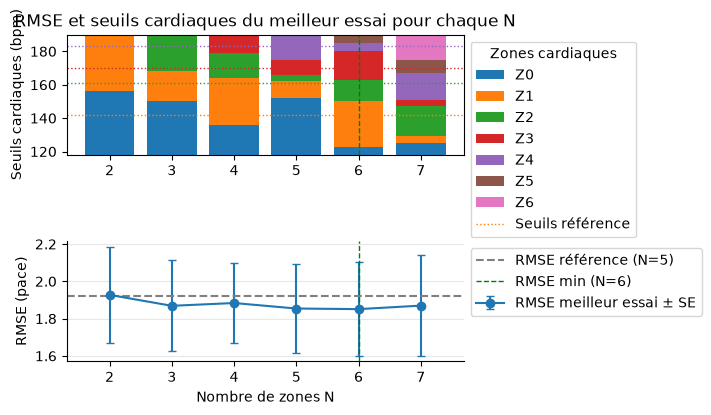

In [165]:
def plot_best_zones_per_n(summary: pd.DataFrame):
    """Seuils cardiaques et RMSE du meilleur essai pour chaque nombre de zones N."""
    summary = summary.sort_index()
    positions = np.arange(len(summary))
    n_values = summary.index.to_numpy()
    max_n = int(n_values.max())

    fig, axes = plt.subplots(
        figsize=(7, 4), nrows=2, ncols=1, sharex=True, constrained_layout=True
    )

    # floating stacked bars: one bar per N, each segment spans one zone [lo, hi]
    # (loop over N and zone index, i.e. over parameters, not over data rows)
    for position, cuts in zip(positions, summary["cuts"], strict=True):
        for k, (lo, hi) in enumerate(cuts_to_zones(cuts).values()):
            axes[0].bar(
                position,
                hi - lo,
                bottom=lo,
                width=0.8,
                color=ZONE_COLORS[k],
                label=f"Z{k}",
            )

    # RMSE of the best trial for each N, with the standard error over the folds
    axes[1].errorbar(
        positions,
        summary["rmse"],
        yerr=summary["rmse_se"],
        fmt="o-",
        capsize=3,
        label="RMSE meilleur essai ± SE",
    )
    axes[1].axhline(
        y=REFERENCE_RMSE,
        color="gray",
        linestyle="--",
        label=f"RMSE référence (N={len(REFERENCE_CUTS) + 1})",
    )

    # title, axes labels and limits
    all_cuts = np.concatenate(summary["cuts"].map(np.asarray).to_numpy())
    axes[0].set_title("RMSE et seuils cardiaques du meilleur essai pour chaque N")
    axes[0].set_ylabel("Seuils cardiaques (bpm)")
    axes[0].set_ylim(all_cuts.min() - 5, all_cuts.max() + 5)

    axes[1].set_ylabel(f"RMSE ({dataset.target_name})")
    axes[1].set_xlabel("Nombre de zones N")
    axes[1].set_xticks(positions, n_values)
    axes[0].tick_params(axis="x", labelbottom=True)

    axes[1].grid(axis="y", alpha=0.3)
    axes[1].spines[["top", "right"]].set_visible(False)

    # reference cuts as horizontal lines, coloured like the zone they open
    # (cut c_{k+1} is the lower bound of Z{k+1}); single legend entry
    for k, cut in enumerate(REFERENCE_CUTS):
        axes[0].axhline(
            y=cut,
            color=ZONE_COLORS[k + 1],
            linestyle=":",
            linewidth=1,
            label="Seuils référence" if k == 0 else "_nolegend_",
        )

    # highlight the N with the lowest RMSE on both axes
    best_position = int(np.argmin(summary["rmse"].to_numpy()))
    for ax, label in zip(
        axes,
        ["_nolegend_", f"RMSE min (N={n_values[best_position]})"],
        strict=True,
    ):
        ax.axvline(
            x=best_position, color="green", linestyle="--", linewidth=1, label=label
        )

    # legends: one entry per zone index, ordered Z0 ... Z{max_n - 1}
    handles, labels = axes[0].get_legend_handles_labels()
    zone_handles = dict(zip(labels, handles, strict=True))
    legend_labels = [f"Z{k}" for k in range(max_n)] + ["Seuils référence"]
    axes[0].legend(
        [zone_handles[label] for label in legend_labels],
        legend_labels,
        title="Zones cardiaques",
        loc="upper left",
        bbox_to_anchor=(1, 1),
    )
    _ = axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))
    return fig, axes


fig, axes = plot_best_zones_per_n(summary)
plt.show()

In [166]:
# RMSE en fonction de chaque paramètre (c1, gap_k) pour le N retenu
optuna.visualization.plot_slice(studies[SELECTED_N]).show()

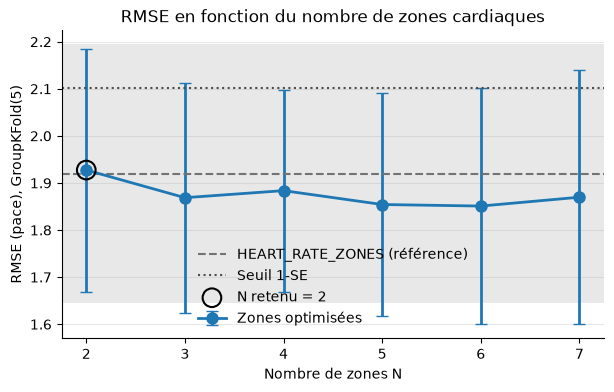

In [167]:
import matplotlib.pyplot as plt

# RMSE (meilleur essai) en fonction de N, avec barres d'erreur = erreur standard sur les plis
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(
    summary.index,
    summary["rmse"],
    yerr=summary["rmse_se"],
    fmt="o-",
    color="tab:blue",
    linewidth=2,
    markersize=8,
    capsize=4,
    label="Zones optimisées",
)
ax.axhline(
    REFERENCE_RMSE,
    color="0.45",
    linestyle="--",
    linewidth=1.5,
    label="HEART_RATE_ZONES (référence)",
)
ax.axhspan(
    REFERENCE_RMSE - REFERENCE_SE,
    REFERENCE_RMSE + REFERENCE_SE,
    color="0.85",
    alpha=0.6,
    linewidth=0,
)
ax.axhline(
    one_se_threshold, color="0.3", linestyle=":", linewidth=1.5, label="Seuil 1-SE"
)
ax.scatter(
    [SELECTED_N],
    [summary.at[SELECTED_N, "rmse"]],
    s=180,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    zorder=3,
    label=f"N retenu = {SELECTED_N}",
)
ax.set_xticks(summary.index)
ax.set_xlabel("Nombre de zones N")
ax.set_ylabel(f"RMSE ({dataset.target_name}), GroupKFold({N_SPLITS})")
ax.set_title("RMSE en fonction du nombre de zones cardiaques")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()